# Assessment of Soil Microplastic Contamination: Distribution, Soil Properties, and Agricultural Practices

In [141]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# PROJECT DIRECTORIES

PROJECT_DIR = os.getcwd()

DATA_DIR = os.path.join(PROJECT_DIR, "raw data")
FIG_DIR = "figures"
TABLE_DIR = "tables"
OUTPUT_DIR = "cleaned_data"

# CREATE OUTPUT FOLDERS

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# VISUALIZATION SETTINGS

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

print("Project setup completed.")
print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)

Project setup completed.
Project directory: c:\Users\Nishat PC\Desktop\soil_microplastic
Data directory: c:\Users\Nishat PC\Desktop\soil_microplastic\raw data


In [142]:
FILES = {
    "mp_quant": "surveympquantification.csv",
    "soil_props": "surveysoilproperties.csv",
    "questionnaire": "surveyquestionnaire.csv",
    "mp_id": "surveympidentification.csv",
    "std_quant": "standardmpquantification.csv",
    "std_polymer": "standardpolymerid.csv",
    "std_lib_uk": "standardpolymerlibrarycomparisonuk.csv",
    "lab_meta": "laboratorymetadata.csv"
}

print("Total datasets:", len(FILES))

for name, filename in FILES.items():
    print(name, ":", filename)

Total datasets: 8
mp_quant : surveympquantification.csv
soil_props : surveysoilproperties.csv
questionnaire : surveyquestionnaire.csv
mp_id : surveympidentification.csv
std_quant : standardmpquantification.csv
std_polymer : standardpolymerid.csv
std_lib_uk : standardpolymerlibrarycomparisonuk.csv
lab_meta : laboratorymetadata.csv


# 3. LOAD ALL DATASETS

In [143]:
data = {}

for name, filename in FILES.items():

    path = os.path.join(DATA_DIR, filename)

    if os.path.exists(path):

        try:
            data[name] = pd.read_csv(
                path,
                encoding="latin1"
            )

            print(
                f"[OK] {name}: "
                f"{data[name].shape[0]} rows x "
                f"{data[name].shape[1]} columns"
            )

        except Exception as e:
            data[name] = None
            print(f"[ERROR] {filename}: {e}")

    else:
        data[name] = None
        print(f"[MISSING] {filename}")


# CHECK REQUIRED DATASETS

required_datasets = [
    "mp_quant",
    "soil_props",
    "questionnaire"
]

for name in required_datasets:

    if data[name] is None:
        raise FileNotFoundError(
            f"Required dataset is missing: {FILES[name]}"
        )


# LOADING SUMMARY

loaded_count = sum(
    df is not None for df in data.values()
)

print("\nDATASET LOADING SUMMARY")
print("-----------------------")
print("Total datasets:", len(FILES))
print("Successfully loaded:", loaded_count)
print("Not loaded:", len(FILES) - loaded_count)

print("\nRequired datasets are available.")

[OK] mp_quant: 576 rows x 5 columns
[OK] soil_props: 576 rows x 9 columns
[OK] questionnaire: 192 rows x 49 columns
[OK] mp_id: 6851 rows x 5 columns
[OK] std_quant: 188 rows x 4 columns
[OK] std_polymer: 1440 rows x 5 columns
[OK] std_lib_uk: 180 rows x 5 columns
[OK] lab_meta: 8 rows x 45 columns

DATASET LOADING SUMMARY
-----------------------
Total datasets: 8
Successfully loaded: 8
Not loaded: 0

Required datasets are available.


#4. INITIAL DATASET INSPECTION

In [144]:
# INITIAL DATASET INSPECTION

for name, df in data.items():

    if df is None:
        continue

    print("\n" + "=" * 60)
    print("DATASET:", name)
    print("Shape:", df.shape)
    print("=" * 60)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nFirst 3 rows:")
    print(df.head(3))


DATASET: mp_quant
Shape: (576, 5)

Column names:
['Site', 'Country', 'Depth', 'Z', 'MP_number']

Data types:
Site             str
Country          str
Depth          int64
Z            float64
MP_number    float64
dtype: object

First 3 rows:
  Site Country  Depth         Z    MP_number
0   E1   Egypt     10 -0.279410   877.381883
1   E1   Egypt     20 -0.662864   744.294969
2   E1   Egypt     30  1.501901  1495.628188

DATASET: soil_props
Shape: (576, 9)

Column names:
['Site Code', 'Country', 'Depth', 'pH', 'EC', 'NH4', 'NO3', 'DOC', 'PO4']

Data types:
Site Code        str
Country          str
Depth          int64
pH           float64
EC           float64
NH4          float64
NO3          float64
DOC          float64
PO4          float64
dtype: object

First 3 rows:
  Site Code Country  Depth    pH     EC    NH4   NO3     DOC   PO4
0        E1   Egypt     10  8.95  290.0  33.19  2.37  264.28  6.93
1        E1   Egypt     20  9.20  337.0  25.40  3.18  199.75  7.10
2        E1   Egyp

# 5. INITIAL DATA QUALITY REPORT

In [145]:
# INITIAL DATA QUALITY REPORT

quality_reports = []

for name, df in data.items():

    if df is None:
        continue

    report = pd.DataFrame({
        "Dataset": name,
        "Column": df.columns,
        "Data_Type": [str(df[col].dtype) for col in df.columns],
        "Missing_Values": [df[col].isna().sum() for col in df.columns],
        "Missing_Percentage": [
            round(df[col].isna().mean() * 100, 2)
            for col in df.columns
        ],
        "Unique_Values": [df[col].nunique() for col in df.columns]
    })

    quality_reports.append(report)

    print(f"\nDataset: {name}")
    print("Duplicate rows:", df.duplicated().sum())


# COMBINE ALL QUALITY REPORTS

quality_report = pd.concat(
    quality_reports,
    ignore_index=True
)

# DISPLAY QUALITY REPORT

quality_report = quality_report.sort_values(
    by=["Dataset", "Missing_Percentage"],
    ascending=[True, False]
)

quality_report


Dataset: mp_quant
Duplicate rows: 0

Dataset: soil_props
Duplicate rows: 0

Dataset: questionnaire
Duplicate rows: 0

Dataset: mp_id
Duplicate rows: 236

Dataset: std_quant
Duplicate rows: 0

Dataset: std_polymer
Duplicate rows: 0

Dataset: std_lib_uk
Duplicate rows: 0

Dataset: lab_meta
Duplicate rows: 0


,Dataset,Column,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
111,lab_meta,Nile_red_CAS_number,str,7,87.5,1
112,lab_meta,Polyethylene_manufacturer,str,7,87.5,1
113,lab_meta,Polyethylene_product_number,float64,7,87.5,1
114,lab_meta,Polyethylene_CAS_number,str,7,87.5,1
115,lab_meta,SD_manufacturer,str,7,87.5,1
...,...,...,...,...,...,...
74,std_polymer,Particle,int64,0,0.0,50
68,std_quant,Country,str,0,0.0,8
69,std_quant,Sample,str,0,0.0,8
70,std_quant,Rep,int64,0,0.0,9


# 6. save quality report

In [146]:
quality_report.to_csv(
    os.path.join(TABLE_DIR, "initial_data_quality_report.csv"),
    index=False
)

print("Initial data quality report saved successfully.")

Initial data quality report saved successfully.


# 7. CLEANING FUNCTIONS

In [147]:
# MISSING VALUE REPRESENTATIONS

missing_values = [
    "",
    "NA",
    "N/A",
    "na",
    "n/a",
    "NULL",
    "null",
    "None",
    "none"
]


# COLUMN NAME STANDARDIZATION

column_aliases = {
    "Site Code": "Site",
    "Site_Code": "Site"
}


# FUNCTION TO CLEAN A DATAFRAME

def clean_dataframe(df):

    cleaned_df = df.copy()

    # Remove extra spaces from column names
    cleaned_df.columns = cleaned_df.columns.str.strip()

    # Standardize inconsistent column names
    cleaned_df = cleaned_df.rename(
        columns=column_aliases
    )

    # Remove extra spaces from text values
    for col in cleaned_df.select_dtypes(include="object").columns:

        cleaned_df[col] = cleaned_df[col].str.strip()

    # Standardize missing values
    cleaned_df = cleaned_df.replace(
        missing_values,
        np.nan
    )

    return cleaned_df


print("Cleaning functions defined successfully.")

Cleaning functions defined successfully.


# 8. test cleaning function

In [148]:
# CLEAN ALL DATASETS

cleaned_data = {}

for name, df in data.items():

    if df is not None:

        cleaned_data[name] = clean_dataframe(df)

        print(
            f"{name}: "
            f"{cleaned_data[name].shape[0]} rows x "
            f"{cleaned_data[name].shape[1]} columns"
        )

print("\nAll available datasets cleaned successfully.")

mp_quant: 576 rows x 5 columns
soil_props: 576 rows x 9 columns
questionnaire: 192 rows x 49 columns


C:\Users\Nishat PC\AppData\Local\Temp\ipykernel_9264\3816132760.py:39: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in cleaned_df.select_dtypes(include="object").columns:
C:\Users\Nishat PC\AppData\Local\Temp\ipykernel_9264\3816132760.py:39: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/

mp_id: 6851 rows x 5 columns
std_quant: 188 rows x 4 columns
std_polymer: 1440 rows x 5 columns
std_lib_uk: 180 rows x 5 columns
lab_meta: 8 rows x 45 columns

All available datasets cleaned successfully.


In [149]:
# MAIN CLEANED DATASETS

mp_quant_clean = cleaned_data["mp_quant"]
soil_props_clean = cleaned_data["soil_props"]
questionnaire_clean = cleaned_data["questionnaire"]

mp_id_clean = cleaned_data["mp_id"]
std_quant_clean = cleaned_data["std_quant"]
std_polymer_clean = cleaned_data["std_polymer"]
std_lib_uk_clean = cleaned_data["std_lib_uk"]
lab_meta_clean = cleaned_data["lab_meta"]

9: Convert numeric columns correctly

# 9. Clean the main survey datasets

In [150]:
# NUMERIC COLUMNS FOR EACH DATASET

numeric_columns = {

    "mp_quant": [
        "Depth", "Z", "MP_number"
    ],

    "soil_props": [
        "Depth", "pH", "EC", "NH4",
        "NO3", "DOC", "PO4"
    ],

    "questionnaire": [
        "Max_cultivation_depth",
        "Annual_average_rainfall",
        "Annual_average_air_temperature",
        "PMF_use_duration",
        "Coated_fertiliser_use_duration",
        "Compost_quantity_per_year",
        "Compost_use_duration",
        "Sewage_sludge_quantity_per_year",
        "Sewage_sludge_use_duration"
    ],

    "mp_id": [
        "Depth", "Quality"
    ],

    "std_quant": [
        "Rep", "Particle_number"
    ],

    "std_polymer": [
        "Sample", "Particle", "MatchQuality"
    ],

    "std_lib_uk": [
        "Library", "Sample", "Particle", "MatchQuality"
    ],

    "lab_meta": [
        "Membrane_area", "Membrane_d",
        "Real_membrane_d", "Real_membrane_a",
        "Pore_size", "Emission_wavelength",
        "Nile_red_purity"
    ]
}


# CONVERT NUMERIC COLUMNS

numeric_conversion_report = []

for name, columns in numeric_columns.items():

    df = cleaned_data[name]

    for col in columns:

        if col in df.columns:

            original_non_missing = df[col].notna()

            converted = pd.to_numeric(
                df[col],
                errors="coerce"
            )

            failed_conversions = (
                original_non_missing & converted.isna()
            ).sum()

            numeric_conversion_report.append({
                "Dataset": name,
                "Column": col,
                "Failed_Conversions": failed_conversions
            })

            df[col] = converted


numeric_conversion_report = pd.DataFrame(
    numeric_conversion_report
)

numeric_conversion_report

,Dataset,Column,Failed_Conversions
0,mp_quant,Depth,0
1,mp_quant,Z,0
2,mp_quant,MP_number,0
3,soil_props,Depth,0
4,soil_props,pH,0
5,soil_props,EC,0
6,soil_props,NH4,0
7,soil_props,NO3,0
8,soil_props,DOC,0
9,soil_props,PO4,0


# 10. Compare missing values before and after cleaning

In [151]:
# COMPARE ORIGINAL AND CLEANED DATASETS

cleaning_summary = []

for name in cleaned_data:

    original_df = data[name]
    cleaned_df = cleaned_data[name]

    cleaning_summary.append({

        "Dataset": name,

        "Original_Rows": original_df.shape[0],
        "Cleaned_Rows": cleaned_df.shape[0],

        "Original_Columns": original_df.shape[1],
        "Cleaned_Columns": cleaned_df.shape[1],

        "Original_Missing": original_df.isna().sum().sum(),
        "Cleaned_Missing": cleaned_df.isna().sum().sum(),

        "Original_Duplicates": original_df.duplicated().sum(),
        "Cleaned_Duplicates": cleaned_df.duplicated().sum()

    })


cleaning_summary = pd.DataFrame(cleaning_summary)

cleaning_summary

,Dataset,Original_Rows,Cleaned_Rows,Original_Columns,Cleaned_Columns,Original_Missing,Cleaned_Missing,Original_Duplicates,Cleaned_Duplicates
0,mp_quant,576,576,5,5,8,8,0,0
1,soil_props,576,576,9,9,6,6,0,0
2,questionnaire,192,192,49,49,656,656,0,0
3,mp_id,6851,6851,5,5,0,0,236,236
4,std_quant,188,188,4,4,0,0,0,0
5,std_polymer,1440,1440,5,5,220,220,0,0
6,std_lib_uk,180,180,5,5,0,0,0,0
7,lab_meta,8,8,45,45,98,98,0,0


# 11. Save the cleaning summary

In [152]:
cleaning_summary.to_csv(
    os.path.join(TABLE_DIR, "cleaning_summary.csv"),
    index=False
)

numeric_conversion_report.to_csv(
    os.path.join(TABLE_DIR, "numeric_conversion_report.csv"),
    index=False
)

print("Cleaning reports saved successfully.")

Cleaning reports saved successfully.


# 12: Missing value analysis for all datasets

In [153]:
# MISSING VALUE ANALYSIS

missing_report = []

for name, df in cleaned_data.items():

    for col in df.columns:

        missing_count = df[col].isna().sum()

        missing_report.append({
            "Dataset": name,
            "Column": col,
            "Missing_Count": missing_count,
            "Missing_Percentage": round(
                df[col].isna().mean() * 100, 2
            )
        })


missing_report = pd.DataFrame(missing_report)

# SHOW ONLY COLUMNS WITH MISSING VALUES

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
]

missing_report = missing_report.sort_values(
    by=["Dataset", "Missing_Percentage"],
    ascending=[True, False]
)

missing_report

,Dataset,Column,Missing_Count,Missing_Percentage
111,lab_meta,Nile_red_CAS_number,7,87.50
112,lab_meta,Polyethylene_manufacturer,7,87.50
113,lab_meta,Polyethylene_product_number,7,87.50
114,lab_meta,Polyethylene_CAS_number,7,87.50
115,lab_meta,SD_manufacturer,7,87.50
116,lab_meta,SD_product_number,7,87.50
117,lab_meta,SD_CAS_number,7,87.50
118,lab_meta,BT_manufacturer,7,87.50
119,lab_meta,BT_product_number,7,87.50
120,lab_meta,BT_CAS_number,7,87.50


# 13: Save the missing value report

In [154]:
missing_report.to_csv(
    os.path.join(TABLE_DIR, "missing_value_report.csv"),
    index=False
)

print("Missing value report saved successfully.")

Missing value report saved successfully.


# 14: Visualize missing values

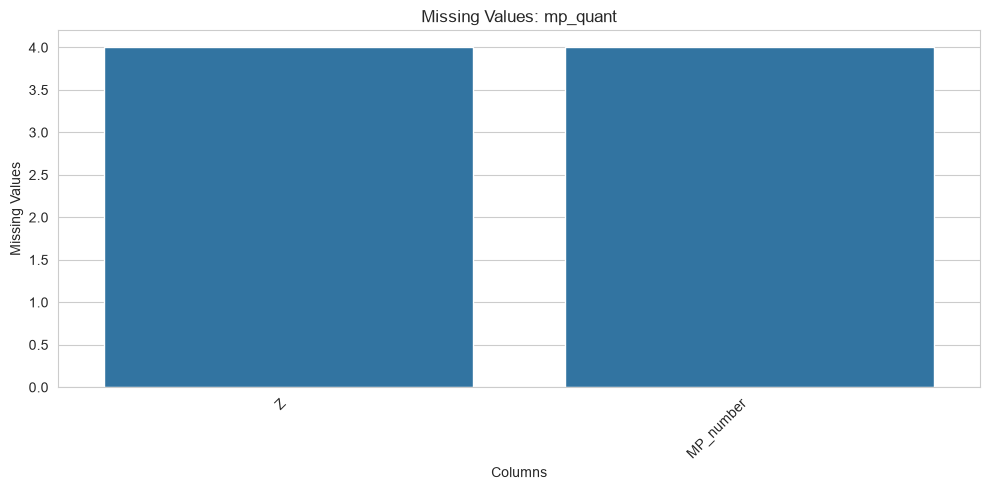

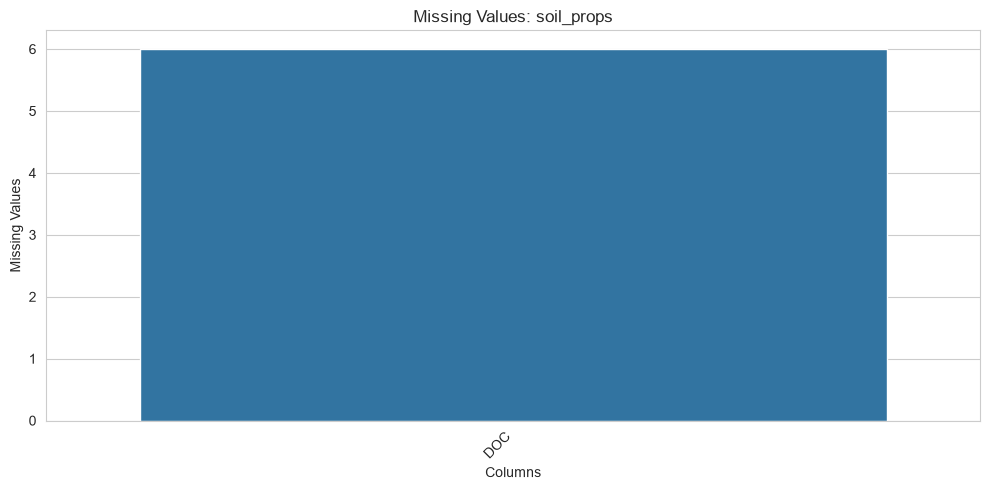

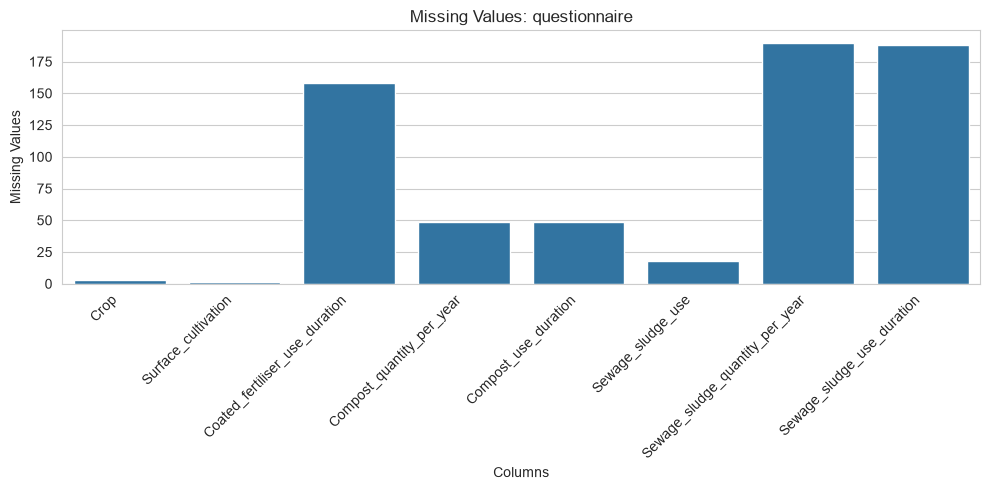

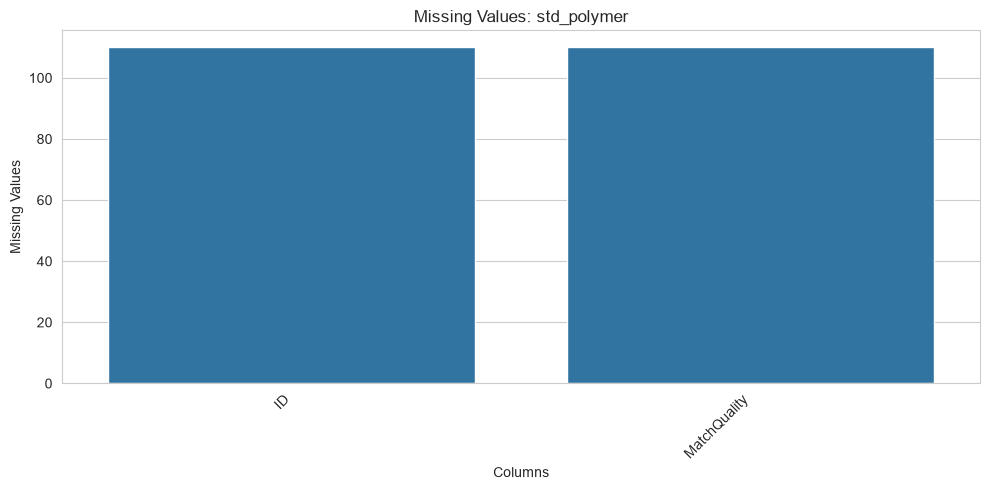

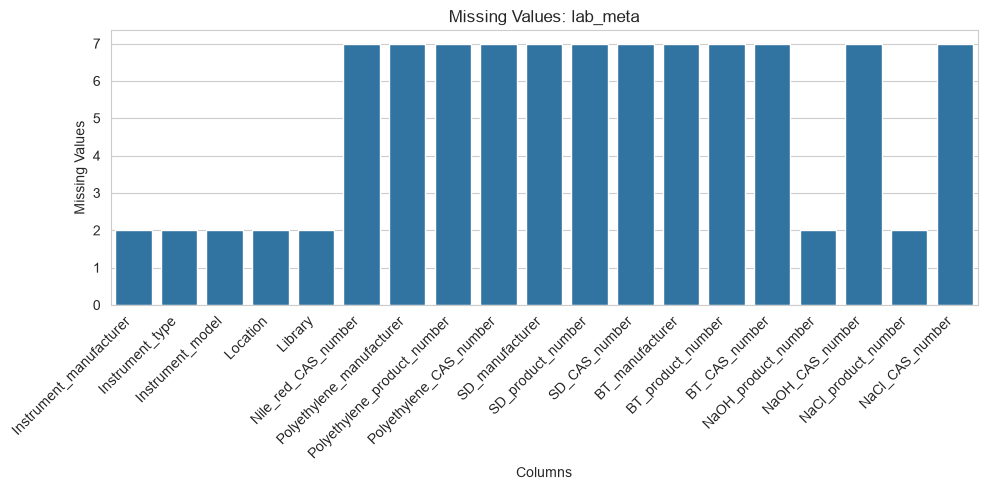

In [155]:
# MISSING VALUE VISUALIZATION

for name, df in cleaned_data.items():

    missing_counts = df.isna().sum()

    missing_counts = missing_counts[
        missing_counts > 0
    ]

    if missing_counts.empty:
        continue

    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=missing_counts.index,
        y=missing_counts.values
    )

    plt.title(f"Missing Values: {name}")
    plt.xlabel("Columns")
    plt.ylabel("Missing Values")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIG_DIR,
            f"{name}_missing_values.png"
        ),
        bbox_inches="tight"
    )

    plt.show()

# 15: Investigate questionnaire missing values

In [156]:
# QUESTIONNAIRE MISSING VALUE INVESTIGATION

conditional_fields = {
    "Coated_fertiliser_use": [
        "Coated_fertiliser_use_duration"
    ],

    "Compost_use": [
        "Compost_quantity_per_year",
        "Compost_use_duration"
    ],

    "Sewage_sludge_use": [
        "Sewage_sludge_quantity_per_year",
        "Sewage_sludge_use_duration"
    ]
}

for question, related_fields in conditional_fields.items():

    print("\nQuestion:", question)

    print("\nResponse distribution:")
    print(questionnaire_clean[question].value_counts(dropna=False))

    for field in related_fields:

        print(f"\nMissing {field} by {question}:")

        print(
            questionnaire_clean.groupby(
                question,
                dropna=False
            )[field]
            .apply(lambda x: x.isna().sum())
        )


Question: Coated_fertiliser_use

Response distribution:
Coated_fertiliser_use
No     154
Yes     38
Name: count, dtype: int64

Missing Coated_fertiliser_use_duration by Coated_fertiliser_use:
Coated_fertiliser_use
No     154
Yes      4
Name: Coated_fertiliser_use_duration, dtype: int64

Question: Compost_use

Response distribution:
Compost_use
Yes    146
No      46
Name: count, dtype: int64

Missing Compost_quantity_per_year by Compost_use:
Compost_use
No     46
Yes     3
Name: Compost_quantity_per_year, dtype: int64

Missing Compost_use_duration by Compost_use:
Compost_use
No     46
Yes     3
Name: Compost_use_duration, dtype: int64

Question: Sewage_sludge_use

Response distribution:
Sewage_sludge_use
No     170
NaN     18
Yes      4
Name: count, dtype: int64

Missing Sewage_sludge_quantity_per_year by Sewage_sludge_use:
Sewage_sludge_use
No     170
Yes      2
NaN     18
Name: Sewage_sludge_quantity_per_year, dtype: int64

Missing Sewage_sludge_use_duration by Sewage_sludge_use:
Sew

# 16: Check duplicate records

In [157]:
# DUPLICATE RECORD ANALYSIS

duplicate_report = []

for name, df in cleaned_data.items():

    duplicate_count = df.duplicated().sum()

    duplicate_report.append({
        "Dataset": name,
        "Total_Rows": len(df),
        "Duplicate_Rows": duplicate_count,
        "Duplicate_Percentage": round(
            (duplicate_count / len(df)) * 100, 2
        ) if len(df) > 0 else 0
    })


duplicate_report = pd.DataFrame(duplicate_report)

duplicate_report

,Dataset,Total_Rows,Duplicate_Rows,Duplicate_Percentage
0,mp_quant,576,0,0.00
1,soil_props,576,0,0.00
2,questionnaire,192,0,0.00
3,mp_id,6851,236,3.44
4,std_quant,188,0,0.00
5,std_polymer,1440,0,0.00
6,std_lib_uk,180,0,0.00
7,lab_meta,8,0,0.00


# 17: Extract actual duplicate records

In [158]:
# EXTRACT DUPLICATE RECORDS

duplicate_records = {}

for name, df in cleaned_data.items():

    duplicates = df[
        df.duplicated(keep=False)
    ].copy()

    duplicate_records[name] = duplicates

    if not duplicates.empty:

        print(f"\n{name}")
        print("Duplicate records:", len(duplicates))

        print(duplicates.head(5))


mp_id
Duplicate records: 452
    Country Code  Depth  Quality      ID
55    China   C9     10     61.4  Rubber
59    China   C9     10     61.4  Rubber
88    China  C16     10     34.3  Rubber
93    China  C16     10     34.3  Rubber
134   China  C20     10     64.3      PE


# 18: Save duplicate records and report

In [159]:
# SAVE DUPLICATE ANALYSIS

duplicate_report.to_csv(
    os.path.join(TABLE_DIR, "duplicate_report.csv"),
    index=False
)

for name, df in duplicate_records.items():

    if not df.empty:

        df.to_csv(
            os.path.join(
                TABLE_DIR,
                f"{name}_duplicate_records.csv"
            ),
            index=False
        )

print("Duplicate analysis saved successfully.")

Duplicate analysis saved successfully.


# 19: Identify categorical variables

In [160]:
# CATEGORICAL DATA INSPECTION

categorical_report = []

for name, df in cleaned_data.items():

    for col in df.select_dtypes(
        include=["object", "string"]
    ).columns:

        unique_values = df[col].dropna().unique()

        categorical_report.append({
            "Dataset": name,
            "Column": col,
            "Unique_Categories": len(unique_values),
            "Categories": ", ".join(
                map(str, unique_values[:20])
            )
        })


categorical_report = pd.DataFrame(categorical_report)

categorical_report

,Dataset,Column,Unique_Categories,Categories
0,mp_quant,Site,192,"E1, E2, E3, E4, E5, E6, E7, E8, E9, E10, E11, ..."
1,mp_quant,Country,5,"Egypt, Vietnam, Sri Lanka, China, India"
2,soil_props,Site,192,"E1, E2, E3, E4, E5, E6, E7, E8, E9, E10, E11, ..."
3,soil_props,Country,5,"Egypt, Vietnam, Sri Lanka, China, India"
4,questionnaire,Site,192,"E1, E2, E3, E4, E5, E6, E7, E8, E9, E10, E11, ..."
...,...,...,...,...
82,lab_meta,NaOH_product_number,6,"221465, 30225, UN No.1823, AL4159, CL00.1492, ..."
83,lab_meta,NaOH_CAS_number,1,1310-73-2
84,lab_meta,NaCl_manufacturer,7,"Sigma Aldrich, Heng Xing, Sinopharm Chemical R..."
85,lab_meta,NaCl_product_number,6,"S9888, 30144, 10019318, AL4105, 5820, 9.32641E+12"


# 20: Standardize Yes/No responses

In [161]:
# STANDARDIZE YES/NO RESPONSES

yes_no_columns = [
    "Tillage",
    "Surface_cultivation",
    "Plough",
    "Harrow",
    "Rotavator",
    "Sand",
    "Loam",
    "Silt",
    "Clay",
    "Ploughing",
    "Burning",
    "Waste_collection",
    "Selling",
    "Littering",
    "Recycling",
    "Storage",
    "Reuse",
    "Coated_fertiliser_use",
    "Compost_use",
    "Cow_manure",
    "Chicken_manure",
    "Pig_manure",
    "Sheep_manure",
    "Goat_manure",
    "Microbial_Organic_fertiliser",
    "Commercial_compost",
    "Sewage_sludge_use",
    "Irrigation_pipes",
    "Nets",
    "Greenhouses",
    "Polytunnels",
    "Packaging",
    "Drums",
    "Barriers",
    "Crates"
]

for col in yes_no_columns:

    if col in questionnaire_clean.columns:

        questionnaire_clean[col] = (
            questionnaire_clean[col]
            .str.strip()
            .str.capitalize()
        )


print("Yes/No responses standardized.")

Yes/No responses standardized.


# Check country and polymer categories

In [162]:
# CHECK COUNTRY VALUES

country_datasets = [
    "mp_quant",
    "soil_props",
    "questionnaire",
    "mp_id",
    "std_quant",
    "std_polymer",
    "lab_meta"
]

for name in country_datasets:

    if "Country" in cleaned_data[name].columns:

        print(f"\n{name}")
        print(
            cleaned_data[name]["Country"]
            .value_counts(dropna=False)
        )


# CHECK POLYMER IDENTIFICATION VALUES

for name in ["mp_id", "std_polymer", "std_lib_uk"]:

    print(f"\n{name}: Polymer categories")

    print(
        cleaned_data[name]["ID"]
        .value_counts(dropna=False)
    )


mp_quant
Country
Egypt        120
Vietnam      120
Sri Lanka    120
China        120
India         96
Name: count, dtype: int64

soil_props
Country
Egypt        120
Vietnam      120
Sri Lanka    120
China        120
India         96
Name: count, dtype: int64

questionnaire
Country
Egypt        40
Vietnam      40
Sri Lanka    40
China        40
India        32
Name: count, dtype: int64

mp_id
Country
Sri Lanka    4760
Vietnam       830
Egypt         574
India         387
China         300
Name: count, dtype: int64

std_quant
Country
Australia    28
China_1      27
Egypt        25
UK           24
Vietnam      21
China_2      21
Sri Lanka    21
India        21
Name: count, dtype: int64

std_polymer
Country
UK           240
China        240
Egypt        240
Vietnam      240
Australia    240
India        240
Name: count, dtype: int64

lab_meta
Country
UK           1
China 1      1
China 2      1
Egypt        1
Sri Lanka    1
Vietnam      1
India        1
Australia    1
Name: count, dtype: 

# 22: Save categorical inspection report

In [163]:
categorical_report.to_csv(
    os.path.join(TABLE_DIR, "categorical_quality_report.csv"),
    index=False
)

print("Categorical quality report saved.")

Categorical quality report saved.


# 23: Numeric data quality report

In [164]:
# NUMERIC DATA QUALITY ANALYSIS

numeric_report = []

for name, df in cleaned_data.items():

    for col in df.select_dtypes(include="number").columns:

        numeric_report.append({
            "Dataset": name,
            "Column": col,
            "Minimum": df[col].min(),
            "Maximum": df[col].max(),
            "Mean": round(df[col].mean(), 2),
            "Missing_Values": df[col].isna().sum(),
            "Negative_Values": (df[col] < 0).sum(),
            "Zero_Values": (df[col] == 0).sum()
        })


numeric_report = pd.DataFrame(numeric_report)

numeric_report

,Dataset,Column,Minimum,Maximum,Mean,Missing_Values,Negative_Values,Zero_Values
0,mp_quant,Depth,10.00,30.000000,20.00,0,0,0
1,mp_quant,Z,-2.50,45.577132,0.96,4,279,8
2,mp_quant,MP_number,0.00,42549.634680,900.50,4,0,1
3,soil_props,Depth,10.00,30.000000,20.00,0,0,0
4,soil_props,pH,4.10,9.400000,7.24,0,0,0
5,soil_props,EC,0.16,2660.000000,234.12,0,0,0
6,soil_props,NH4,0.00,280.490000,25.44,0,0,9
7,soil_props,NO3,0.00,570.370000,32.35,0,0,3
8,soil_props,DOC,8.52,6812.750000,176.76,6,0,0
9,soil_props,PO4,1.59,5492.510000,260.22,0,0,0


# 24: Check invalid numeric ranges

In [165]:
# DEFINE NUMERIC VALIDATION RULES

validation_rules = {

    "mp_quant": {
        "MP_number": (0, None),
        "Depth": (10, 30)
    },

    "soil_props": {
        "pH": (0, 14),
        "EC": (0, None),
        "NH4": (0, None),
        "NO3": (0, None),
        "DOC": (0, None),
        "PO4": (0, None),
        "Depth": (10, 30)
    },

    "mp_id": {
        "Quality": (0, 100),
        "Depth": (10, 30)
    },

    "std_quant": {
        "Particle_number": (0, None)
    },

    "std_polymer": {
        "MatchQuality": (0, 100),
        "Particle": (1, None)
    },

    "std_lib_uk": {
        "MatchQuality": (0, 100),
        "Particle": (1, None)
    },

    "lab_meta": {
        "Nile_red_purity": (0, 100)
    }
}


# CHECK VALUES AGAINST RULES

invalid_numeric_records = []

for name, rules in validation_rules.items():

    df = cleaned_data[name]

    for col, (minimum, maximum) in rules.items():

        if col not in df.columns:
            continue

        invalid = pd.Series(False, index=df.index)

        if minimum is not None:
            invalid |= df[col] < minimum

        if maximum is not None:
            invalid |= df[col] > maximum

        for index in df[invalid].index:

            invalid_numeric_records.append({
                "Dataset": name,
                "Column": col,
                "Row_Index": index,
                "Value": df.loc[index, col],
                "Minimum_Allowed": minimum,
                "Maximum_Allowed": maximum
            })


invalid_numeric_records = pd.DataFrame(
    invalid_numeric_records
)

print("Invalid numeric observations:",
      len(invalid_numeric_records))

invalid_numeric_records

Invalid numeric observations: 0


""


# 25: Save numeric quality reports

In [166]:
# SAVE NUMERIC QUALITY REPORTS

numeric_report.to_csv(
    os.path.join(TABLE_DIR, "numeric_quality_report.csv"),
    index=False
)

invalid_numeric_records.to_csv(
    os.path.join(TABLE_DIR, "invalid_numeric_records.csv"),
    index=False
)

print("Numeric quality reports saved successfully.")

Numeric quality reports saved successfully.


# 26: Detect potential outliers using IQR

In [167]:
# IQR OUTLIER DETECTION

outlier_columns = {
    "mp_quant": ["MP_number"],
    "soil_props": ["pH", "EC", "NH4", "NO3", "DOC", "PO4"],
    "std_quant": ["Particle_number"]
}

outlier_records = {}

for name, columns in outlier_columns.items():

    df = cleaned_data[name]

    for col in columns:

        values = df[col].dropna()

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[
            (df[col] < lower_bound) |
            (df[col] > upper_bound)
        ].copy()

        outlier_records[(name, col)] = outliers

        print(f"\nDataset: {name}")
        print("Variable:", col)
        print("Lower bound:", round(lower_bound, 2))
        print("Upper bound:", round(upper_bound, 2))
        print("Potential outliers:", len(outliers))


Dataset: mp_quant
Variable: MP_number
Lower bound: -1214.83
Upper bound: 2051.39
Potential outliers: 48

Dataset: soil_props
Variable: pH
Lower bound: 4.14
Upper bound: 10.35
Potential outliers: 2

Dataset: soil_props
Variable: EC
Lower bound: -361.31
Upper bound: 716.39
Potential outliers: 28

Dataset: soil_props
Variable: NH4
Lower bound: -21.89
Upper bound: 49.22
Potential outliers: 63

Dataset: soil_props
Variable: NO3
Lower bound: -28.7
Upper bound: 64.37
Potential outliers: 72

Dataset: soil_props
Variable: DOC
Lower bound: -96.88
Upper bound: 334.8
Potential outliers: 56

Dataset: soil_props
Variable: PO4
Lower bound: -173.41
Upper bound: 342.48
Potential outliers: 105

Dataset: std_quant
Variable: Particle_number
Lower bound: -1565.43
Upper bound: 2704.2
Potential outliers: 23


# 27: Examine potential outlier observations

In [168]:
# INSPECT POTENTIAL OUTLIERS

for (name, col), outliers in outlier_records.items():

    if not outliers.empty:

        print(f"\n{name} - {col}")
        print(outliers.head(10))


mp_quant - MP_number
    Site    Country  Depth          Z     MP_number
23    E8      Egypt     30   4.211660   2436.114383
25    E9      Egypt     20   3.374877   2145.688805
34   E12      Egypt     20   6.275877   3152.549611
35   E12      Egypt     30   4.041825   2377.169037
42   E15      Egypt     10   4.742290   2620.281933
48   E17      Egypt     10   3.365019   2142.267434
49   E17      Egypt     20   5.818758   2993.895719
61   E21      Egypt     20   3.272074   2110.008786
65   E22      Egypt     30  14.082021   5861.857031
241  SL1  Sri Lanka     20  10.919653  11001.265550

soil_props - pH
    Site  Country  Depth    pH     EC  NH4   NO3    DOC      PO4
154  V12  Vietnam     20  4.10  275.0  6.6  36.6  47.24  1052.68
155  V12  Vietnam     30  4.13  199.0  5.2  16.3  41.76   594.43

soil_props - EC
    Site  Country  Depth    pH      EC    NH4   NO3      DOC      PO4
9     E4    Egypt     10  9.11   918.0  39.39  3.15   168.75    20.79
10    E4    Egypt     20  9.40  1020.

# 28: Visualize outliers using boxplots

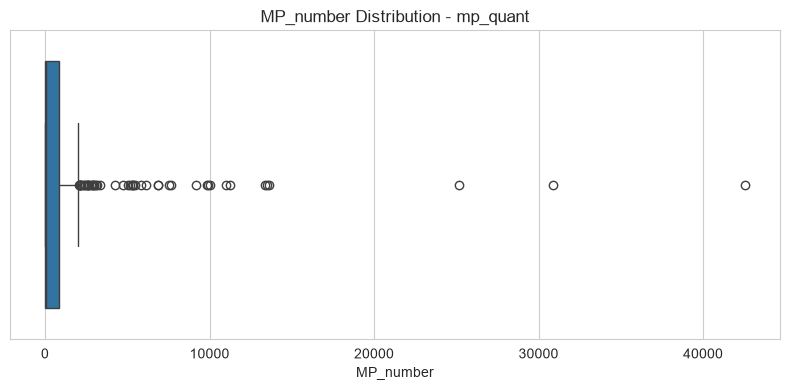

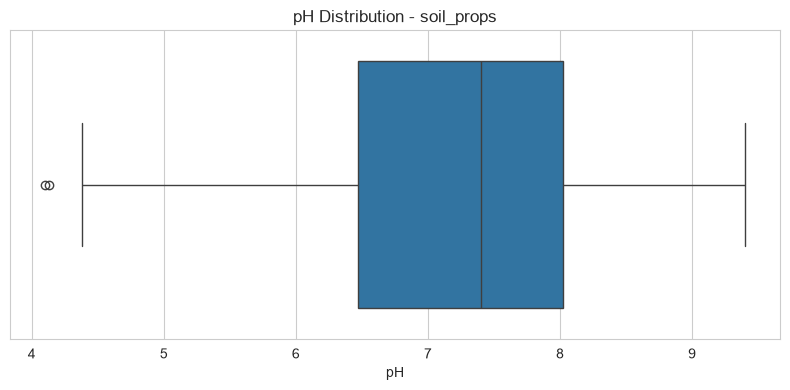

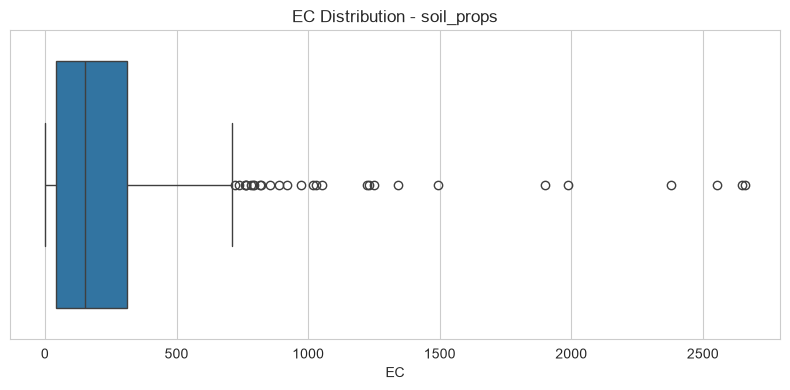

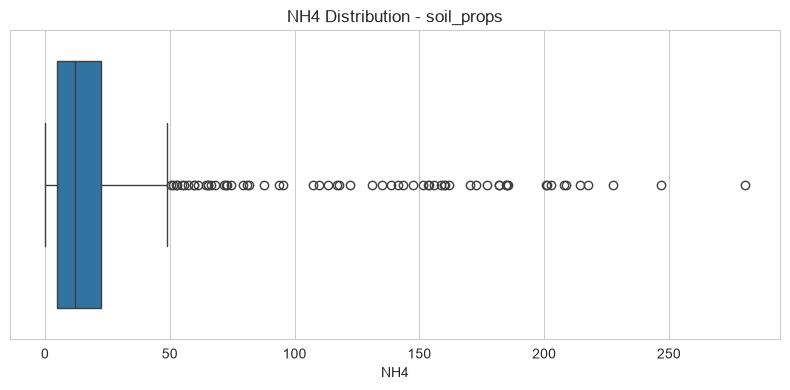

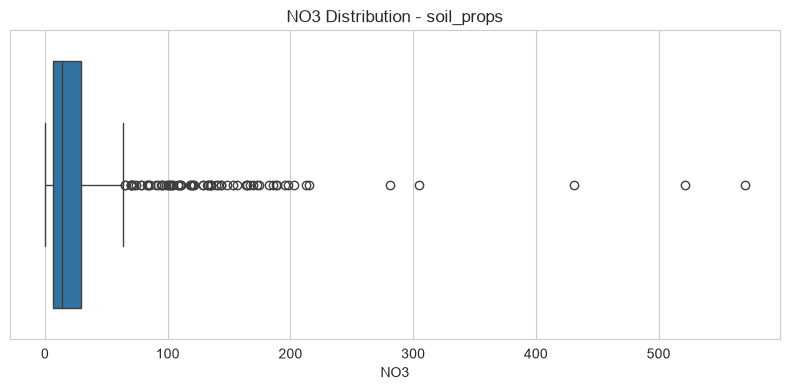

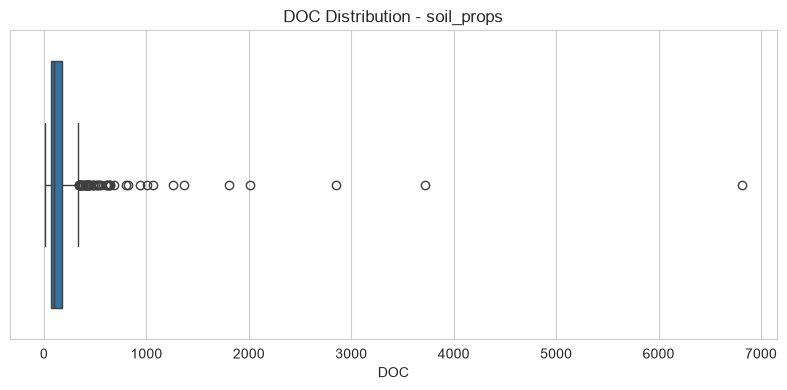

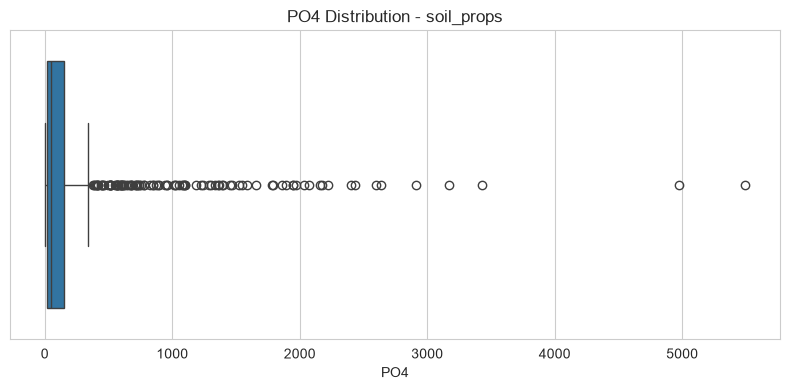

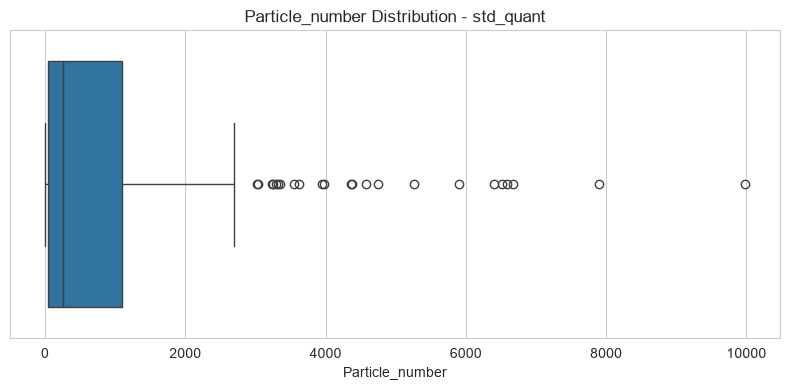

In [169]:
# BOXPLOT ANALYSIS

for name, columns in outlier_columns.items():

    df = cleaned_data[name]

    for col in columns:

        plt.figure(figsize=(8, 4))

        sns.boxplot(x=df[col])

        plt.title(f"{col} Distribution - {name}")
        plt.xlabel(col)

        plt.tight_layout()

        plt.show()

# 29: Validate main survey identifiers

In [170]:
# MAIN SURVEY DATA VALIDATION

print("=" * 60)
print("MAIN SURVEY DATA VALIDATION")
print("=" * 60)

# DEFINE DATASETS AND MERGE KEYS

survey_datasets = {
    "MP Quantification": mp_quant_clean,
    "Soil Properties": soil_props_clean
}

merge_keys = ["Site", "Country", "Depth"]


# CHECK REQUIRED COLUMNS

for name, df in survey_datasets.items():

    missing_columns = [
        col for col in merge_keys
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{name} is missing columns: {missing_columns}"
        )


# CHECK DATA IDENTIFIERS AND DEPTH VALUES

for name, df in survey_datasets.items():

    print(f"\n{name}")

    print(
        "Missing identifiers:",
        df[merge_keys].isna().sum().to_dict()
    )

    print(
        "Duplicate site-depth records:",
        df.duplicated(subset=merge_keys).sum()
    )

    print(
        "Number of unique sites:",
        df["Site"].nunique()
    )

    print(
        "Depth categories:",
        sorted(df["Depth"].dropna().unique())
    )

    bad_depth = df[
        ~df["Depth"].isin([10, 20, 30])
        & df["Depth"].notna()
    ]

    print("Unexpected depth values:", len(bad_depth))


print("\nData validation completed.")

MAIN SURVEY DATA VALIDATION

MP Quantification
Missing identifiers: {'Site': 0, 'Country': 0, 'Depth': 0}
Duplicate site-depth records: 0
Number of unique sites: 192
Depth categories: [np.int64(10), np.int64(20), np.int64(30)]
Unexpected depth values: 0

Soil Properties
Missing identifiers: {'Site': 0, 'Country': 0, 'Depth': 0}
Duplicate site-depth records: 0
Number of unique sites: 192
Depth categories: [np.int64(10), np.int64(20), np.int64(30)]
Unexpected depth values: 0

Data validation completed.


# 30: Check consistency between quantification and soil properties

In [171]:
# CHECK SITE-DEPTH CONSISTENCY

quant_keys = set(
    map(
        tuple,
        mp_quant_clean[merge_keys].drop_duplicates().values
    )
)

soil_keys = set(
    map(
        tuple,
        soil_props_clean[merge_keys].drop_duplicates().values
    )
)

quant_only = quant_keys - soil_keys
soil_only = soil_keys - quant_keys

print("Keys only in MP Quantification:", len(quant_only))
print("Keys only in Soil Properties:", len(soil_only))

if len(quant_only) == 0 and len(soil_only) == 0:
    print("\nBoth datasets contain matching site-depth records.")
else:
    print("\nSome site-depth records do not match.")

Keys only in MP Quantification: 0
Keys only in Soil Properties: 0

Both datasets contain matching site-depth records.


# 31: Validate questionnaire site identifiers

In [172]:
# CHECK QUESTIONNAIRE IDENTIFIERS

questionnaire_keys = ["Site", "Country"]

print("Questionnaire rows:", len(questionnaire_clean))

print(
    "Unique questionnaire sites:",
    questionnaire_clean["Site"].nunique()
)

print(
    "Duplicate questionnaire site records:",
    questionnaire_clean.duplicated(
        subset=questionnaire_keys
    ).sum()
)

print(
    "Missing questionnaire identifiers:",
    questionnaire_clean[questionnaire_keys]
    .isna().sum().to_dict()
)


# CHECK WHETHER QUESTIONNAIRE SITES MATCH QUANTIFICATION SITES

quant_sites = set(
    map(
        tuple,
        mp_quant_clean[questionnaire_keys].drop_duplicates().values
    )
)

questionnaire_sites = set(
    map(
        tuple,
        questionnaire_clean[questionnaire_keys].drop_duplicates().values
    )
)

print(
    "\nSites missing from questionnaire:",
    len(quant_sites - questionnaire_sites)
)

print(
    "Extra sites in questionnaire:",
    len(questionnaire_sites - quant_sites)
)

Questionnaire rows: 192
Unique questionnaire sites: 192
Duplicate questionnaire site records: 0
Missing questionnaire identifiers: {'Site': 0, 'Country': 0}

Sites missing from questionnaire: 0
Extra sites in questionnaire: 0


# 32: Merge the main survey datasets

In [173]:
# MERGE MAIN SURVEY DATASETS

merge_keys = ["Site", "Country", "Depth"]

# STEP 1: MERGE MP QUANTIFICATION AND SOIL PROPERTIES

master_data = pd.merge(
    mp_quant_clean,
    soil_props_clean,
    on=merge_keys,
    how="left",
    validate="one_to_one"
)

print("After merging MP Quantification and Soil Properties:")
print("Rows:", master_data.shape[0])
print("Columns:", master_data.shape[1])


# STEP 2: ADD QUESTIONNAIRE INFORMATION

master_data = pd.merge(
    master_data,
    questionnaire_clean,
    on=["Site", "Country"],
    how="left",
    validate="many_to_one",
    indicator=True
)

# CHECK MERGE RESULTS

print("\nQuestionnaire Merge Results:")
print(master_data["_merge"].value_counts())

# REMOVE MERGE INDICATOR

master_data = master_data.drop(columns=["_merge"])


# FINAL MASTER DATASET SUMMARY

print("\nMASTER DATASET")
print("------------------------------")
print("Rows:", master_data.shape[0])
print("Columns:", master_data.shape[1])
print("Duplicate rows:", master_data.duplicated().sum())

print("\nMaster dataset created successfully.")

After merging MP Quantification and Soil Properties:
Rows: 576
Columns: 11

Questionnaire Merge Results:
_merge
both          576
left_only       0
right_only      0
Name: count, dtype: int64

MASTER DATASET
------------------------------
Rows: 576
Columns: 58
Duplicate rows: 0

Master dataset created successfully.


# 33: Inspect the master dataset

In [174]:
# INSPECT MASTER DATASET

print("Dataset shape:", master_data.shape)

print("\nColumn names:")
print(master_data.columns.tolist())

print("\nFirst 5 rows:")
print(master_data.head())

print("\nData types:")
print(master_data.dtypes)

Dataset shape: (576, 58)

Column names:
['Site', 'Country', 'Depth', 'Z', 'MP_number', 'pH', 'EC', 'NH4', 'NO3', 'DOC', 'PO4', 'Crop', 'Tillage', 'Surface_cultivation', 'Plough', 'Harrow', 'Rotavator', 'Max_cultivation_depth', 'Soil_classification', 'Sand', 'Loam', 'Silt', 'Clay', 'Annual_average_rainfall', 'Annual_average_air_temperature', 'PMF_use_duration', 'PMF_type', 'Ploughing', 'Burning', 'Waste_collection', 'Selling', 'Littering', 'Recycling', 'Storage', 'Reuse', 'Coated_fertiliser_use', 'Coated_fertiliser_use_duration', 'Compost_use', 'Compost_quantity_per_year', 'Cow_manure', 'Chicken_manure', 'Pig_manure', 'Sheep_manure', 'Goat_manure', 'Microbial_Organic_fertiliser', 'Commercial_compost', 'Compost_use_duration', 'Sewage_sludge_use', 'Sewage_sludge_quantity_per_year', 'Sewage_sludge_use_duration', 'Irrigation_pipes', 'Nets', 'Greenhouses', 'Polytunnels', 'Packaging', 'Drums', 'Barriers', 'Crates']

First 5 rows:
  Site Country  Depth         Z    MP_number    pH     EC    NH

# 34: Check master dataset quality

In [175]:
# MASTER DATASET QUALITY CHECK

print("=" * 60)
print("MASTER DATASET QUALITY CHECK")
print("=" * 60)

print("\nDataset shape:", master_data.shape)

print("\nDuplicate rows:", master_data.duplicated().sum())

print("\nMissing values:")
print(
    master_data.isna().sum()
    .sort_values(ascending=False)
)

print("\nMissing value percentage:")
missing_percentage = (
    master_data.isna().mean() * 100
).sort_values(ascending=False)

print(missing_percentage.round(2))

MASTER DATASET QUALITY CHECK

Dataset shape: (576, 58)

Duplicate rows: 0

Missing values:
Sewage_sludge_quantity_per_year    570
Sewage_sludge_use_duration         564
Coated_fertiliser_use_duration     474
Compost_quantity_per_year          147
Compost_use_duration               147
Sewage_sludge_use                   54
Crop                                 9
DOC                                  6
MP_number                            4
Z                                    4
Surface_cultivation                  3
NH4                                  0
NO3                                  0
Tillage                              0
Plough                               0
Harrow                               0
Rotavator                            0
Max_cultivation_depth                0
Soil_classification                  0
Sand                                 0
PO4                                  0
Site                                 0
pH                                   0
EC          

# 35: Save the master dataset

In [176]:
# SAVE MASTER DATASET

master_data.to_csv(
    os.path.join(OUTPUT_DIR, "master_survey_dataset.csv"),
    index=False
)

print("Master survey dataset saved successfully.")

Master survey dataset saved successfully.


# 36: Descriptive statistics

In [177]:
# EDA: DESCRIPTIVE STATISTICS

numeric_summary = master_data.describe().T

numeric_summary = numeric_summary.round(2)

numeric_summary

,count,mean,std,min,25%,50%,75%,max
Depth,576.0,20.00,8.17,10.00,10.00,20.00,30.00,30.00
Z,572.0,0.96,3.77,-2.50,-0.89,0.00,1.50,45.58
MP_number,572.0,900.50,2940.69,0.00,10.00,90.92,826.55,42549.63
pH,576.0,7.24,1.03,4.10,6.47,7.40,8.02,9.40
EC,576.0,234.12,313.97,0.16,42.82,152.00,312.25,2660.00
NH4,576.0,25.44,42.38,0.00,4.78,12.00,22.55,280.49
NO3,576.0,32.35,55.07,0.00,6.20,13.54,29.47,570.37
DOC,570.0,176.76,383.80,8.52,65.00,94.10,172.92,6812.75
PO4,576.0,260.22,572.21,1.59,20.05,50.92,149.02,5492.51
Max_cultivation_depth,576.0,23.58,8.26,0.00,20.00,30.00,30.00,40.00


# 37: Microplastic distribution overview

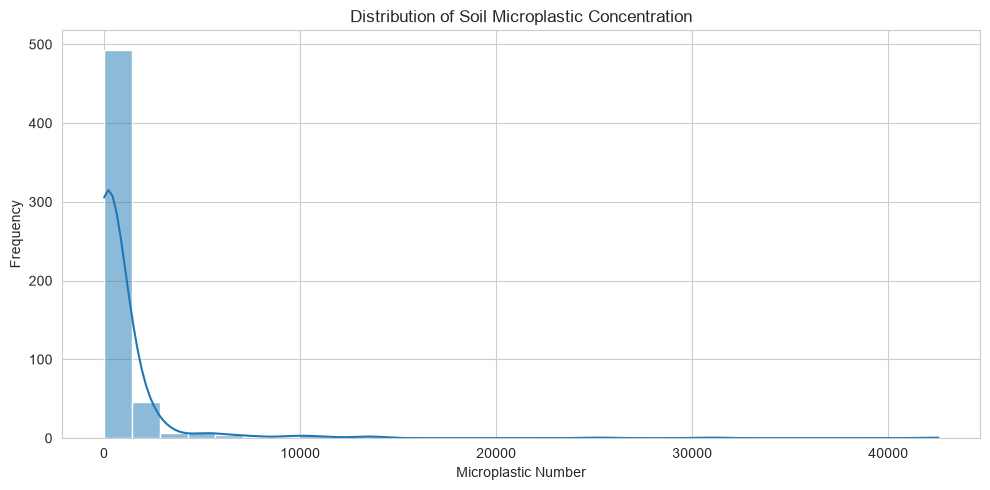

In [178]:
# EDA: MICROPLASTIC DISTRIBUTION

plt.figure(figsize=(10, 5))

sns.histplot(
    data=master_data,
    x="MP_number",
    bins=30,
    kde=True
)

plt.title("Distribution of Soil Microplastic Concentration")
plt.xlabel("Microplastic Number")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "microplastic_distribution.png"),
    bbox_inches="tight"
)

plt.show()

# 38: Average microplastic concentration by country

In [179]:
# EDA: MICROPLASTIC CONCENTRATION BY COUNTRY

country_summary = (
    master_data.groupby("Country")["MP_number"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .sort_values(by="mean", ascending=False)
)

country_summary

,count,mean,median,std
Country,,,,
Sri Lanka,116,3136.71,1110.89,5931.86
Egypt,120,1122.68,974.36,711.38
China,120,76.57,41.38,91.94
India,96,69.56,59.46,42.92
Vietnam,120,5.32,4.40,5.22


# 39: Visualize microplastic concentration by country

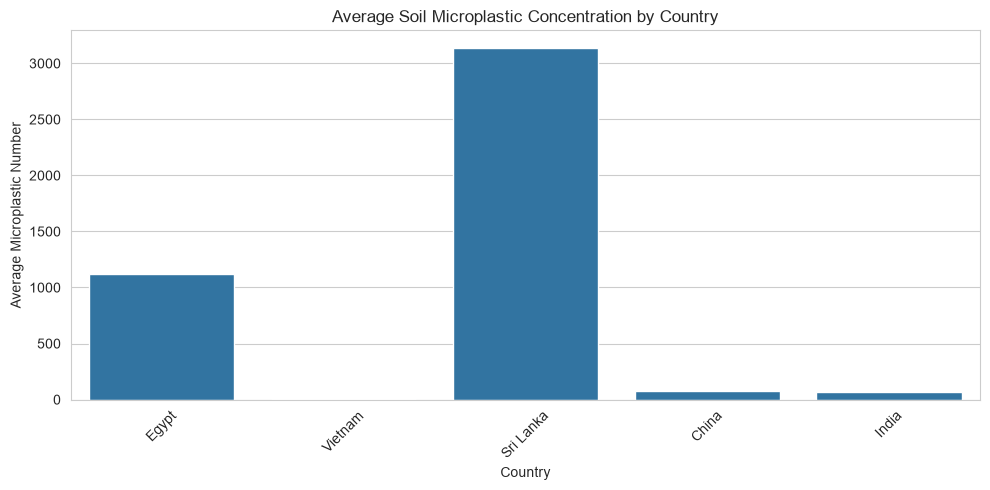

In [180]:
# VISUALIZATION: MICROPLASTIC CONCENTRATION BY COUNTRY

plt.figure(figsize=(10, 5))

sns.barplot(
    data=master_data,
    x="Country",
    y="MP_number",
    errorbar=None
)

plt.title("Average Soil Microplastic Concentration by Country")
plt.xlabel("Country")
plt.ylabel("Average Microplastic Number")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "microplastic_by_country.png"),
    bbox_inches="tight"
)

plt.show()

# 40: Microplastic concentration by soil depth

In [181]:
# EDA: MICROPLASTIC CONCENTRATION BY DEPTH

depth_summary = (
    master_data.groupby("Depth")["MP_number"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

depth_summary

,count,mean,median,std
Depth,,,,
10,190,1043.92,84.37,4380.19
20,190,867.19,92.00,1940.80
30,192,791.53,102.08,1762.52


# 41: Visualize microplastic concentration by depth

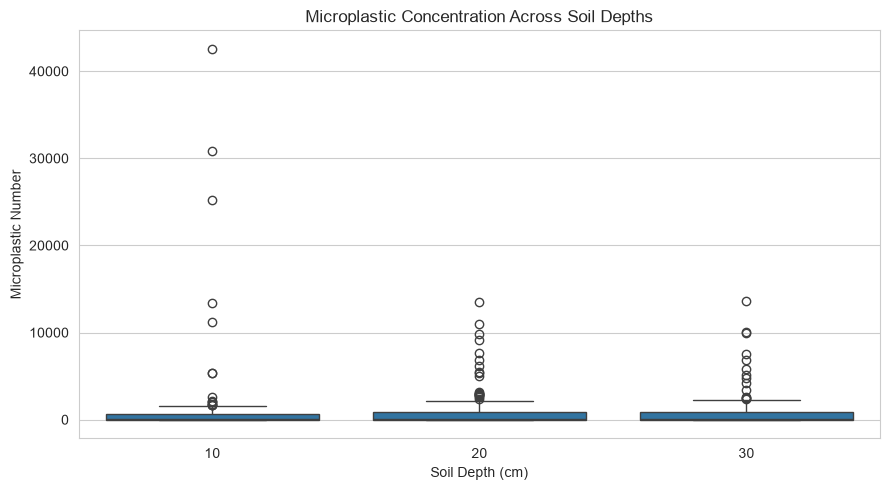

In [182]:
# VISUALIZATION: MICROPLASTIC CONCENTRATION BY DEPTH

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=master_data,
    x="Depth",
    y="MP_number"
)

plt.title("Microplastic Concentration Across Soil Depths")
plt.xlabel("Soil Depth (cm)")
plt.ylabel("Microplastic Number")

plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "microplastic_by_depth.png"),
    bbox_inches="tight"
)

plt.show()

# 42: Correlation analysis

In [183]:
# EDA: CORRELATION WITH SOIL PROPERTIES

soil_columns = [
    "pH", "EC", "NH4", "NO3", "DOC", "PO4"
]

correlation_data = master_data[
    ["MP_number"] + soil_columns
]

correlation_matrix = correlation_data.corr(
    method="pearson"
)

mp_correlations = (
    correlation_matrix["MP_number"]
    .drop("MP_number")
    .sort_values(ascending=False)
)

print("Correlation with Microplastic Number:")
print(mp_correlations.round(3))

Correlation with Microplastic Number:
NH4    0.354
NO3    0.240
DOC    0.042
pH    -0.064
EC    -0.089
PO4   -0.106
Name: MP_number, dtype: float64


# 43: Correlation heatmap

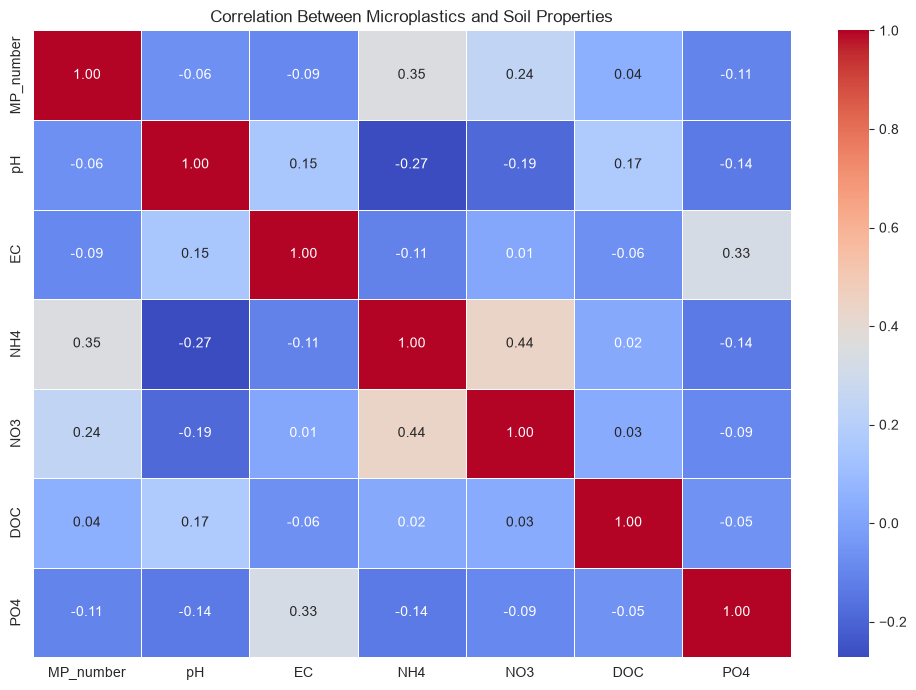

In [184]:
# VISUALIZATION: CORRELATION HEATMAP

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Microplastics and Soil Properties")

plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "soil_property_correlation.png"),
    bbox_inches="tight"
)

plt.show()

# 44: Scatter plots

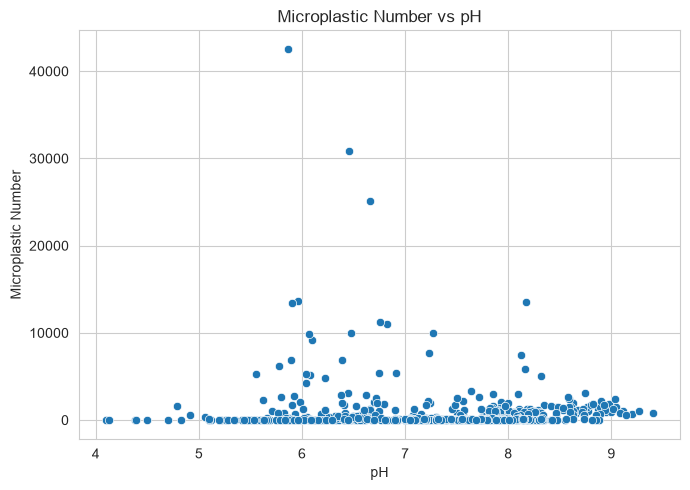

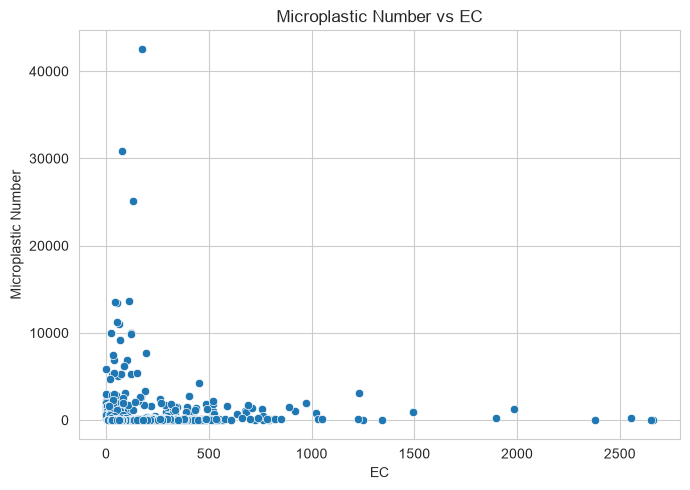

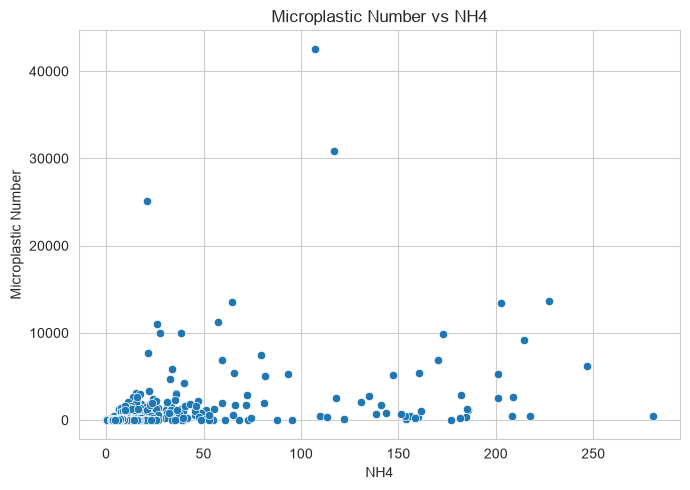

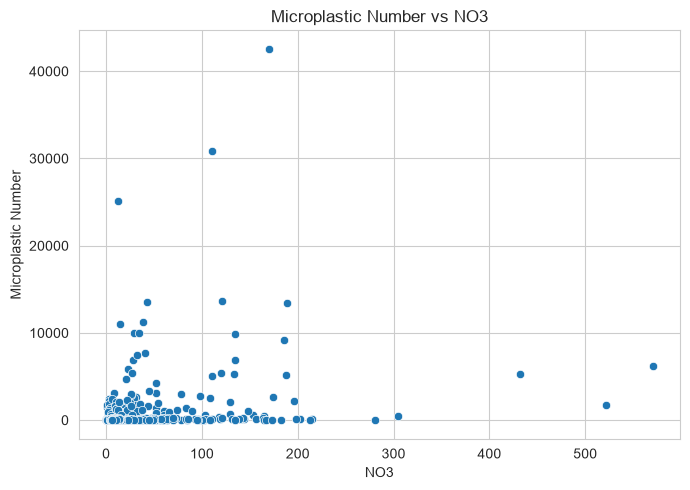

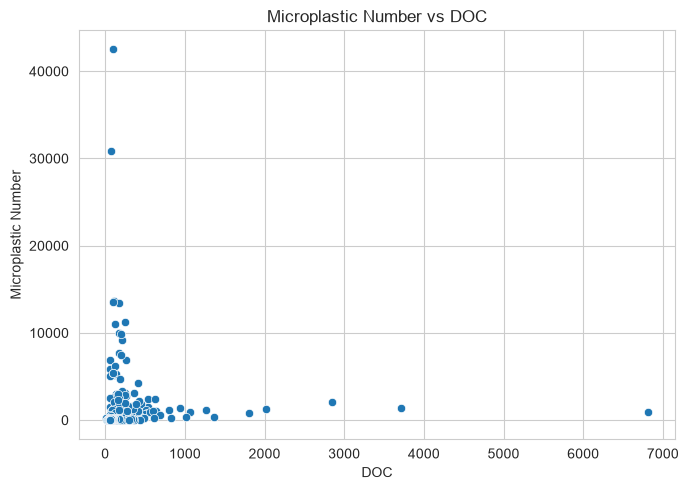

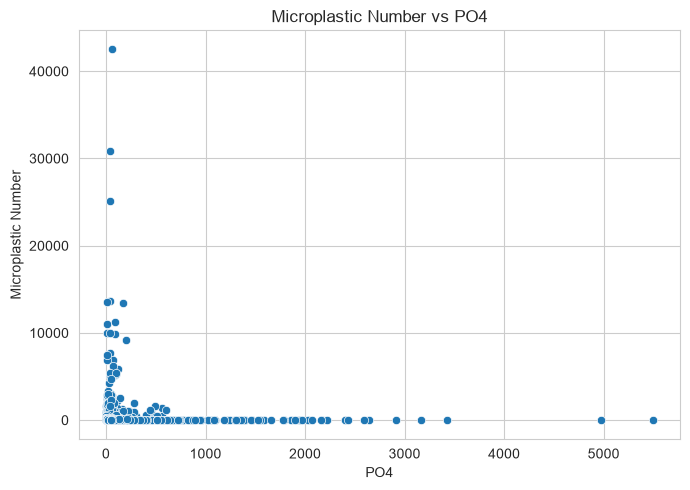

In [185]:
# VISUALIZATION: MICROPLASTICS VS SOIL PROPERTIES

for col in soil_columns:

    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=master_data,
        x=col,
        y="MP_number"
    )

    plt.title(f"Microplastic Number vs {col}")
    plt.xlabel(col)
    plt.ylabel("Microplastic Number")

    plt.tight_layout()

    plt.savefig(
        os.path.join(FIG_DIR, f"mp_vs_{col}.png"),
        bbox_inches="tight"
    )

    plt.show()

# 45: Inspect agricultural practice categories

In [186]:
# EDA: AGRICULTURAL PRACTICE CATEGORIES

practice_columns = [
    "Tillage",
    "Surface_cultivation",
    "Plough",
    "Harrow",
    "Rotavator",
    "PMF_type",
    "Coated_fertiliser_use",
    "Compost_use",
    "Sewage_sludge_use",
    "Irrigation_pipes",
    "Nets",
    "Greenhouses",
    "Polytunnels",
    "Packaging",
    "Drums",
    "Barriers",
    "Crates"
]

for col in practice_columns:

    if col in questionnaire_clean.columns:

        print("\n" + "=" * 45)
        print("Column:", col)
        print(questionnaire_clean[col].value_counts(dropna=False))


Column: Tillage
Tillage
No     152
Yes     40
Name: count, dtype: int64

Column: Surface_cultivation
Surface_cultivation
No     140
Yes     51
NaN      1
Name: count, dtype: int64

Column: Plough
Plough
Yes    97
No     95
Name: count, dtype: int64

Column: Harrow
Harrow
No     108
Yes     84
Name: count, dtype: int64

Column: Rotavator
Rotavator
No     145
Yes     47
Name: count, dtype: int64

Column: PMF_type
PMF_type
LDPE         188
LDPE, PVC      4
Name: count, dtype: int64

Column: Coated_fertiliser_use
Coated_fertiliser_use
No     154
Yes     38
Name: count, dtype: int64

Column: Compost_use
Compost_use
Yes    146
No      46
Name: count, dtype: int64

Column: Sewage_sludge_use
Sewage_sludge_use
No     170
NaN     18
Yes      4
Name: count, dtype: int64

Column: Irrigation_pipes
Irrigation_pipes
No     106
Yes     86
Name: count, dtype: int64

Column: Nets
Nets
No     182
Yes     10
Name: count, dtype: int64

Column: Greenhouses
Greenhouses
No     169
Yes     23
Name: count, dty

# 46: Visualize selected agricultural practices

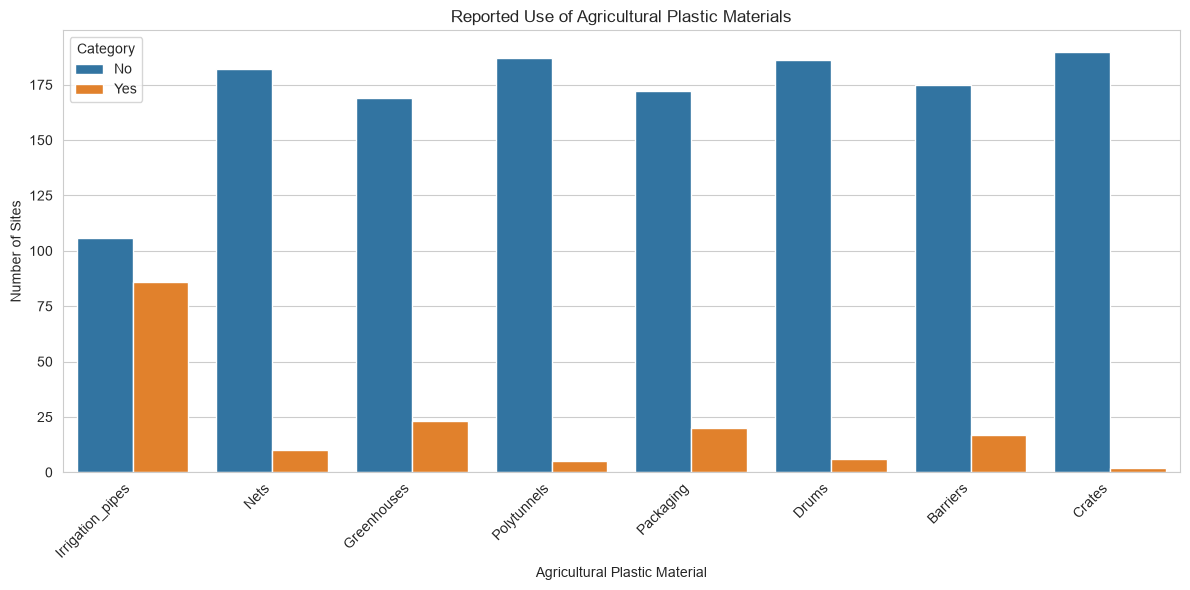

In [187]:
# VISUALIZATION: AGRICULTURAL PLASTIC MATERIALS

plastic_columns = [
    "Irrigation_pipes",
    "Nets",
    "Greenhouses",
    "Polytunnels",
    "Packaging",
    "Drums",
    "Barriers",
    "Crates"
]

plastic_usage = []

for col in plastic_columns:

    if col in questionnaire_clean.columns:

        counts = questionnaire_clean[col].value_counts()

        for category, count in counts.items():

            plastic_usage.append({
                "Material": col,
                "Category": category,
                "Count": count
            })

plastic_usage = pd.DataFrame(plastic_usage)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plastic_usage,
    x="Material",
    y="Count",
    hue="Category"
)

plt.title("Reported Use of Agricultural Plastic Materials")
plt.xlabel("Agricultural Plastic Material")
plt.ylabel("Number of Sites")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "agricultural_plastic_usage.png"),
    bbox_inches="tight"
)

plt.show()

# 47: Compare microplastic concentration by agricultural practices

In [188]:
# AGRICULTURAL PRACTICES VS MICROPLASTIC CONCENTRATION

practice_analysis_columns = [
    "Irrigation_pipes",
    "Nets",
    "Greenhouses",
    "Polytunnels",
    "Packaging",
    "Compost_use",
    "Coated_fertiliser_use"
]

practice_results = []

for col in practice_analysis_columns:

    if col in master_data.columns:

        summary = (
            master_data.groupby(col)["MP_number"]
            .agg(["count", "mean", "median"])
            .reset_index()
        )

        summary["Practice"] = col

        summary = summary.rename(
            columns={col: "Category"}
        )

        practice_results.append(summary)


practice_comparison = pd.concat(
    practice_results,
    ignore_index=True
)

practice_comparison = practice_comparison[
    ["Practice", "Category", "count", "mean", "median"]
]

practice_comparison.round(2)

,Practice,Category,count,mean,median
0,Irrigation_pipes,No,315,478.14,45.59
1,Irrigation_pipes,Yes,257,1418.18,785.64
2,Nets,No,542,837.64,96.00
3,Nets,Yes,30,2036.20,4.80
4,Greenhouses,No,503,974.70,114.97
5,Greenhouses,Yes,69,359.59,37.04
6,Polytunnels,No,557,799.41,85.49
7,Polytunnels,Yes,15,4654.40,814.19
8,Packaging,No,516,746.25,73.06
9,Packaging,Yes,56,2321.84,819.71


# 48: Visualize agricultural practice comparisons

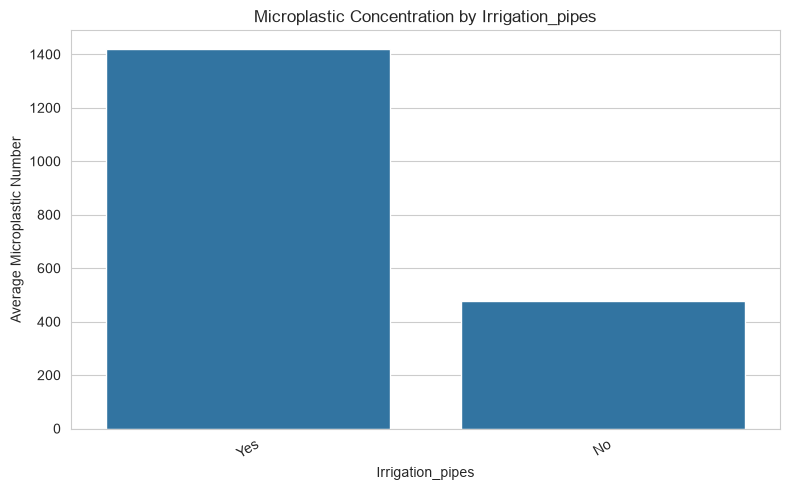

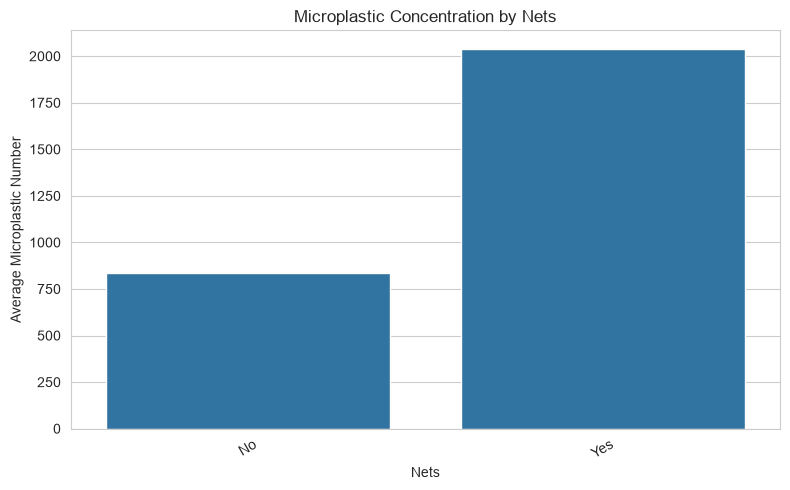

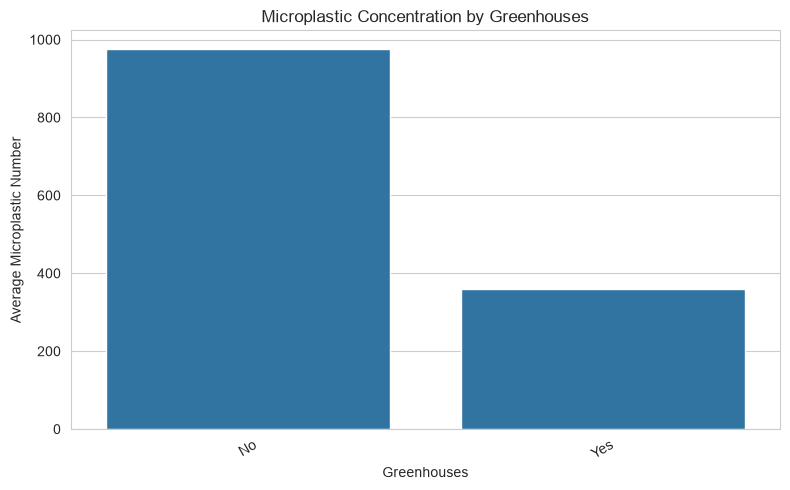

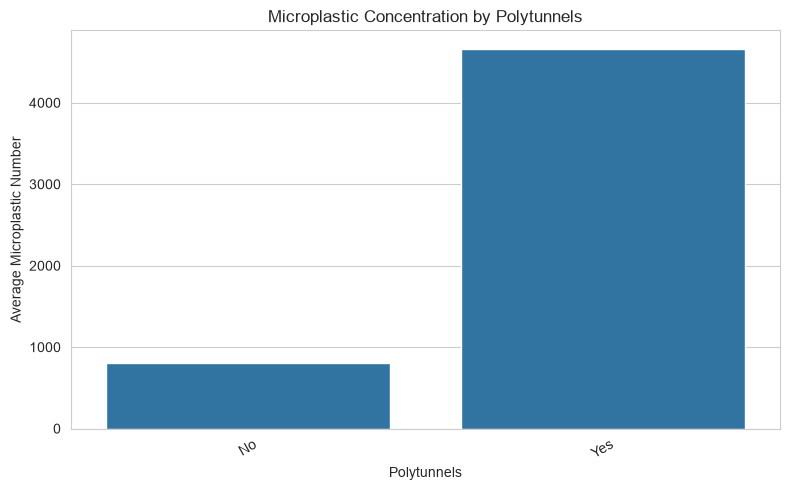

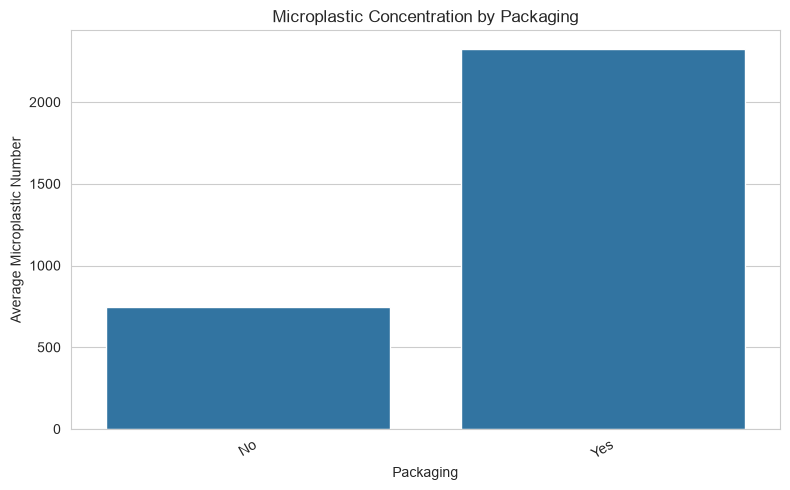

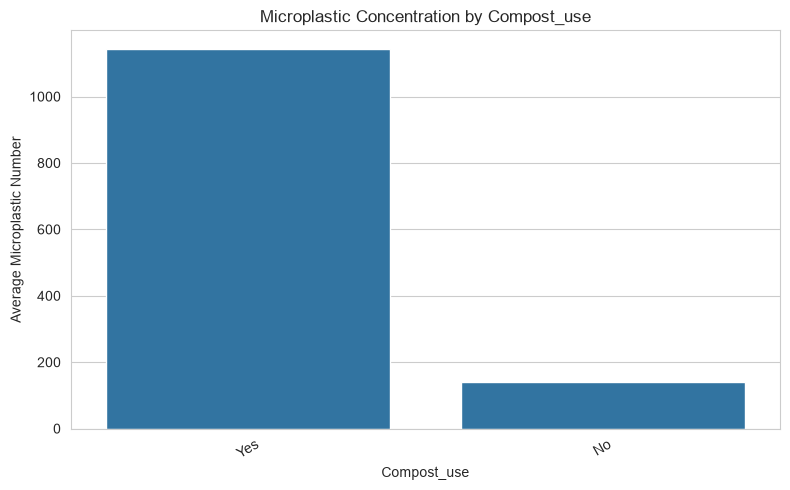

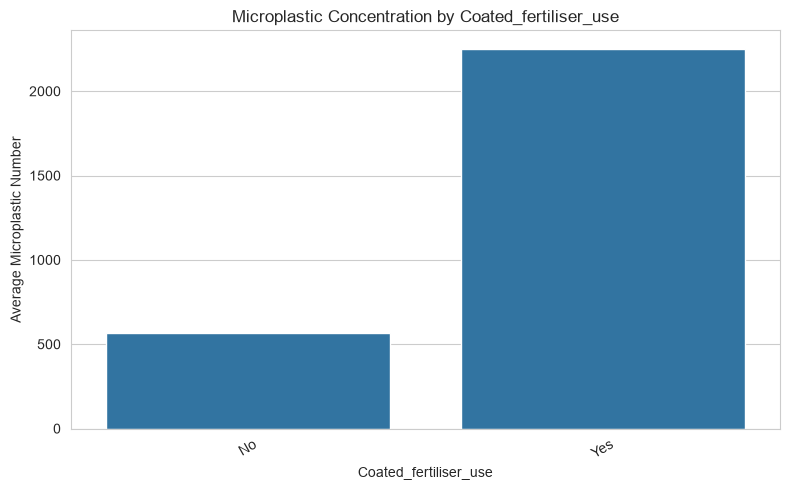

In [189]:
# VISUALIZATION: AGRICULTURAL PRACTICES VS MICROPLASTICS

for col in practice_analysis_columns:

    if col in master_data.columns:

        plt.figure(figsize=(8, 5))

        sns.barplot(
            data=master_data,
            x=col,
            y="MP_number",
            errorbar=None
        )

        plt.title(f"Microplastic Concentration by {col}")
        plt.xlabel(col)
        plt.ylabel("Average Microplastic Number")
        plt.xticks(rotation=30)

        plt.tight_layout()

        plt.savefig(
            os.path.join(FIG_DIR, f"mp_by_{col}.png"),
            bbox_inches="tight"
        )

        plt.show()

# 49: Analyze identified polymer types
# EDA: Polymer identification

In [190]:
# EDA: POLYMER IDENTIFICATION FREQUENCY

polymer_summary = (
    mp_id_clean["ID"]
    .value_counts()
    .reset_index()
)

polymer_summary.columns = [
    "Polymer",
    "Frequency"
]

polymer_summary["Percentage"] = (
    polymer_summary["Frequency"]
    / polymer_summary["Frequency"].sum()
    * 100
).round(2)

polymer_summary

,Polymer,Frequency,Percentage
0,Rubber,2212,32.29
1,PA,2064,30.13
2,PS,515,7.52
3,PET,444,6.48
4,PP,408,5.96
5,PE,330,4.82
6,PU,192,2.80
7,PVA,164,2.39
8,PVC,115,1.68
9,PLA,98,1.43


# 50: Visualize polymer identification

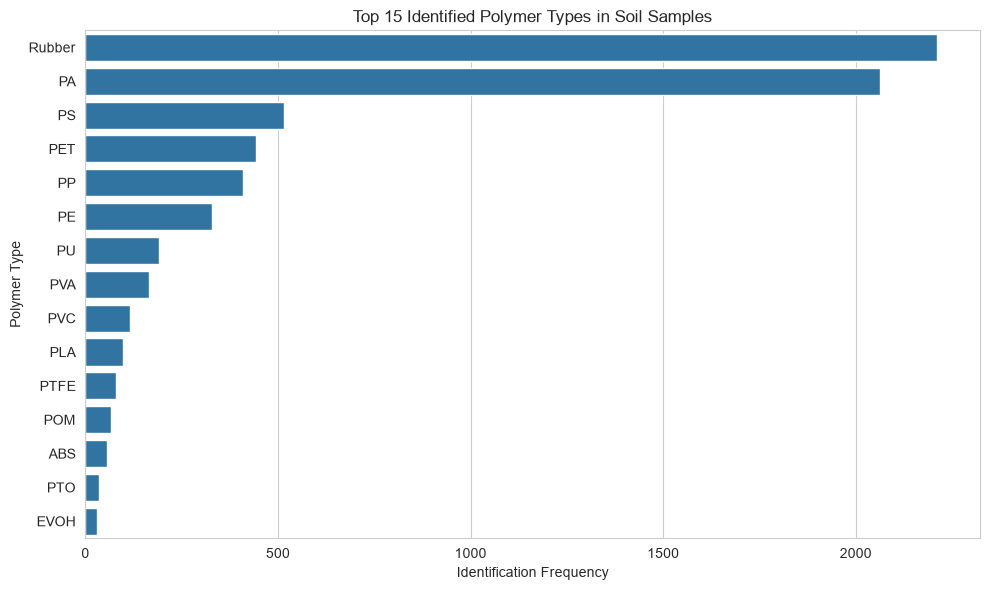

In [191]:
# VISUALIZATION: POLYMER IDENTIFICATION

top_polymers = polymer_summary.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_polymers,
    x="Frequency",
    y="Polymer"
)

plt.title("Top 15 Identified Polymer Types in Soil Samples")
plt.xlabel("Identification Frequency")
plt.ylabel("Polymer Type")

plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "polymer_identification.png"),
    bbox_inches="tight"
)

plt.show()

# 51: Generate the analysis summary

In [192]:
# FINAL EDA SUMMARY

eda_summary = pd.DataFrame({
    "Analysis": [
        "Total survey observations",
        "Number of countries",
        "Number of unique sites",
        "Average microplastic number",
        "Median microplastic number",
        "Minimum microplastic number",
        "Maximum microplastic number",
        "Number of identified polymer types"
    ],

    "Result": [
        len(master_data),
        master_data["Country"].nunique(),
        master_data["Site"].nunique(),
        round(master_data["MP_number"].mean(), 2),
        round(master_data["MP_number"].median(), 2),
        master_data["MP_number"].min(),
        master_data["MP_number"].max(),
        mp_id_clean["ID"].nunique()
    ]
})

eda_summary

,Analysis,Result
0,Total survey observations,576.00000
1,Number of countries,5.00000
2,Number of unique sites,192.00000
3,Average microplastic number,900.50000
4,Median microplastic number,90.92000
5,Minimum microplastic number,0.00000
6,Maximum microplastic number,42549.63468
7,Number of identified polymer types,20.00000


# 52: Save final analysis outputs

In [193]:
# SAVE FINAL ANALYSIS OUTPUTS

eda_summary.to_csv(
    os.path.join(TABLE_DIR, "final_eda_summary.csv"),
    index=False
)

country_summary.to_csv(
    os.path.join(TABLE_DIR, "country_comparison.csv")
)

depth_summary.to_csv(
    os.path.join(TABLE_DIR, "depth_comparison.csv")
)

mp_correlations.to_csv(
    os.path.join(TABLE_DIR, "soil_property_correlations.csv")
)

practice_comparison.to_csv(
    os.path.join(TABLE_DIR, "agricultural_practice_comparison.csv"),
    index=False
)

polymer_summary.to_csv(
    os.path.join(TABLE_DIR, "polymer_identification_summary.csv"),
    index=False
)

master_data.to_csv(
    os.path.join(OUTPUT_DIR, "master_survey_dataset.csv"),
    index=False
)

print("Final analysis outputs saved successfully.")

Final analysis outputs saved successfully.


# 53: Inspect duplicate polymer records

In [194]:
# INVESTIGATE DUPLICATE POLYMER IDENTIFICATION RECORDS

mp_id_duplicates = mp_id_clean[
    mp_id_clean.duplicated(keep=False)
].copy()

print("Total duplicate records:", len(mp_id_duplicates))

print("\nDuplicate records by country:")
print(
    mp_id_duplicates["Country"]
    .value_counts()
)

print("\nSample duplicate records:")
mp_id_duplicates.head(10)

Total duplicate records: 452

Duplicate records by country:
Country
Sri Lanka    363
India         45
Egypt         28
China         10
Vietnam        6
Name: count, dtype: int64

Sample duplicate records:


,Country,Code,Depth,Quality,ID
55,China,C9,10,61.4,Rubber
59,China,C9,10,61.4,Rubber
88,China,C16,10,34.3,Rubber
93,China,C16,10,34.3,Rubber
134,China,C20,10,64.3,PE
142,China,C20,10,64.3,PE
150,China,C22,10,31.6,Rubber
151,China,C22,10,31.6,Rubber
171,China,C24,10,48.3,Rubber
175,China,C24,10,48.3,Rubber


# 54: Check whether duplicates affect polymer frequencies

In [195]:
# COMPARE POLYMER FREQUENCIES BEFORE AND AFTER DUPLICATE REMOVAL

mp_id_unique = mp_id_clean.drop_duplicates().copy()

polymer_frequency_comparison = pd.DataFrame({
    "Original_Frequency": mp_id_clean["ID"].value_counts(),
    "After_Duplicate_Removal": mp_id_unique["ID"].value_counts()
}).fillna(0).astype(int)

polymer_frequency_comparison["Difference"] = (
    polymer_frequency_comparison["Original_Frequency"]
    - polymer_frequency_comparison["After_Duplicate_Removal"]
)

polymer_frequency_comparison = (
    polymer_frequency_comparison
    .sort_values("Original_Frequency", ascending=False)
)

polymer_frequency_comparison

,Original_Frequency,After_Duplicate_Removal,Difference
ID,,,
Rubber,2212,2067,145
PA,2064,2025,39
PS,515,490,25
PET,444,442,2
PP,408,403,5
PE,330,326,4
PU,192,182,10
PVA,164,162,2
PVC,115,114,1


# 55: Save final data-quality investigation

In [196]:
# SAVE FINAL DATA QUALITY INVESTIGATION

mp_id_duplicates.to_csv(
    os.path.join(
        TABLE_DIR,
        "polymer_identification_duplicates.csv"
    ),
    index=False
)

polymer_frequency_comparison.to_csv(
    os.path.join(
        TABLE_DIR,
        "polymer_frequency_comparison.csv"
    )
)

# SAVE FINAL MASTER DATASET

master_data.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "master_survey_dataset.csv"
    ),
    index=False
)

print("Final data-quality investigation saved.")
print("Master survey dataset saved.")
print("Main analysis outputs are ready.")

Final data-quality investigation saved.
Master survey dataset saved.
Main analysis outputs are ready.
